# Dimensionality reduction of the Iris dataset with PCA

The four Iris measurements are standardised and reduced with **principal component analysis**. Explained variance, loadings, a 2-D biplot and the reconstruction error are shown. Logistic regression accuracy (10-fold cross-validation) is compared on 4, 3, 2 and 1 dimensions.

The data is `Iris.csv`, the Kaggle/UCI version included here. If it is missing, scikit-learn's built-in copy is used instead. That copy corrects 2 rows (35 and 38), so the results differ very slightly. Figures are written to `figures/` and the scores to `results.json`.

In [1]:
import json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
DATA = Path("Iris.csv")   # the copy shipped with this project (scikit-learn's built-in copy differs in 2 rows)
if not DATA.exists():   # fall back to the copy built into scikit-learn
    from sklearn.datasets import load_iris
    b = load_iris(as_frame=True); df = b.frame.rename(columns={"target": "Species"})
    df["Species"] = df["Species"].map(dict(enumerate(["Iris-setosa", "Iris-versicolor", "Iris-virginica"])))
    df.columns = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]
else:
    df = pd.read_csv(DATA).drop(columns="Id")
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X, y = df[features].to_numpy(), df["Species"].to_numpy()
print(df.shape, "| missing:", int(df.isna().sum().sum())); print(df["Species"].value_counts().to_dict())
df.describe().round(2)

(150, 5) | missing: 0
{'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 1. Standardise

PCA looks for the directions with the most variance, so a feature measured on a bigger scale would dominate. Each feature is rescaled to mean 0 and standard deviation 1.

In [2]:
print("std before scaling:", X.std(axis=0).round(3))
Xs = StandardScaler().fit_transform(X)
print("mean after:", Xs.mean(axis=0).round(3), " std after:", Xs.std(axis=0).round(3))
print("correlation matrix:\n", pd.DataFrame(np.corrcoef(Xs.T), index=features, columns=features).round(3))

std before scaling: [0.825 0.432 1.759 0.761]
mean after: [-0. -0.  0. -0.]  std after: [1. 1. 1. 1.]
correlation matrix:
                SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm          1.000        -0.109          0.872         0.818
SepalWidthCm          -0.109         1.000         -0.421        -0.357
PetalLengthCm          0.872        -0.421          1.000         0.963
PetalWidthCm           0.818        -0.357          0.963         1.000


## 2. Apply PCA (all 4 components)

The explained variance ratio says how much of the total variance each component keeps. The loadings say how much each original feature contributes to each component.

PC1:  72.77%   cumulative  72.77%   eigenvalue 2.9304
PC2:  23.03%   cumulative  95.80%   eigenvalue 0.9274
PC3:   3.68%   cumulative  99.48%   eigenvalue 0.1483
PC4:   0.52%   cumulative 100.00%   eigenvalue 0.0207
                 PC1    PC2    PC3    PC4
SepalLengthCm  0.522  0.372  0.721 -0.262
SepalWidthCm  -0.263  0.926 -0.242  0.124
PetalLengthCm  0.581  0.021 -0.141  0.801
PetalWidthCm   0.566  0.065 -0.634 -0.524


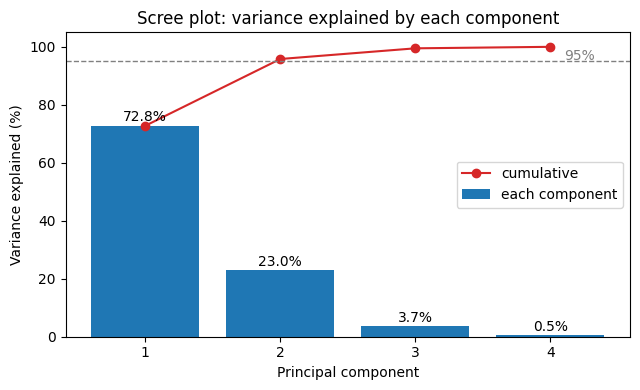

In [3]:
pca = PCA().fit(Xs)
evr = pca.explained_variance_ratio_; cum = np.cumsum(evr)
for i, (e, c) in enumerate(zip(evr, cum), 1):
    print(f"PC{i}: {e*100:6.2f}%   cumulative {c*100:6.2f}%   eigenvalue {pca.explained_variance_[i-1]:.4f}")
loadings = pd.DataFrame(pca.components_.T, index=features, columns=[f"PC{i}" for i in range(1, 5)])
print(loadings.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(range(1, 5), evr * 100, label="each component")
ax.plot(range(1, 5), cum * 100, "o-", color="tab:red", label="cumulative")
ax.axhline(95, ls="--", color="grey", lw=1); ax.text(4.1, 95.5, "95%", color="grey")
for i, v in enumerate(evr * 100, 1): ax.text(i, v + 1.5, f"{v:.1f}%", ha="center")
ax.set_xticks(range(1, 5)); ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained (%)"); ax.set_ylim(0, 105)
ax.set_title("Scree plot: variance explained by each component"); ax.legend(loc="center right")
plt.tight_layout(); plt.savefig(FIG / "scree.png", dpi=150); plt.show()

## 3. Reduce to 2 dimensions

The 150 flowers are projected onto PC1 and PC2. The arrows (a biplot) show the direction each original feature points in the new space.

reduced shape: (150, 2) | variance kept: 95.8 %


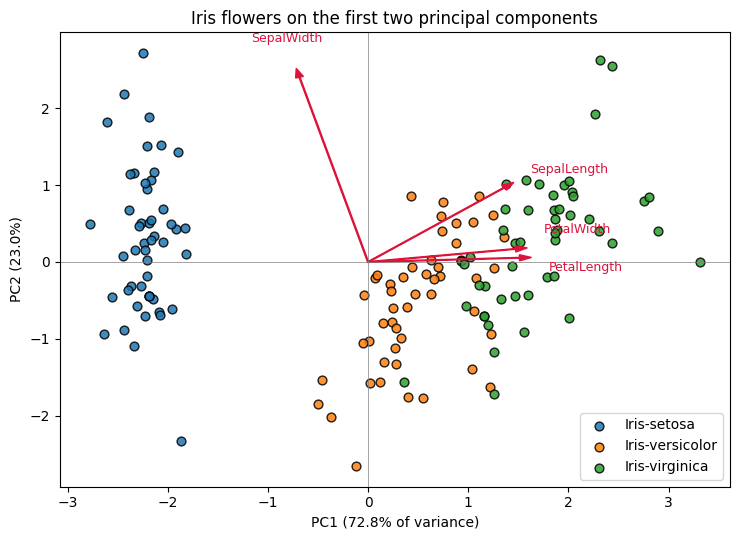

reconstruction error (mean squared, standardised units): 0.042


In [4]:
Z = PCA(n_components=2).fit(Xs)
X2 = Z.transform(Xs)
print("reduced shape:", X2.shape, "| variance kept:", round(Z.explained_variance_ratio_.sum() * 100, 2), "%")
colors = {"Iris-setosa": "tab:blue", "Iris-versicolor": "tab:orange", "Iris-virginica": "tab:green"}
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s, c in colors.items():
    m = y == s; ax.scatter(X2[m, 0], X2[m, 1], c=c, label=s, edgecolor="k", s=40, alpha=0.85)
for f, (a, b) in zip(features, Z.components_.T):
    ax.arrow(0, 0, a * 2.6, b * 2.6, color="crimson", width=0.01, head_width=0.08)
    nudge = {"PetalWidthCm": 0.18, "PetalLengthCm": -0.18}.get(f, 0.0)   # keep the two petal labels apart
    ax.text(a * 3.1, b * 3.1 + nudge, f.replace("Cm", ""), color="crimson", ha="left" if a > 0 else "center", fontsize=9)
ax.set_xlabel(f"PC1 ({Z.explained_variance_ratio_[0]*100:.1f}% of variance)"); ax.set_ylabel(f"PC2 ({Z.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Iris flowers on the first two principal components"); ax.legend(); ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
plt.tight_layout(); plt.savefig(FIG / "pca_2d.png", dpi=150); plt.show()
recon = Z.inverse_transform(X2)
print("reconstruction error (mean squared, standardised units):", round(float(np.mean((Xs - recon) ** 2)), 4))

## 4. Does the reduction keep enough information?

A logistic regression is trained on 4, 3, 2 and 1 dimensions and scored with 10-fold cross-validation. Scaling and PCA sit inside a pipeline so they are re-fitted on each training fold and no test information leaks in.

original 4 features    accuracy 95.33% (± 5.21)


PCA 3 component(s)     accuracy 95.33% (± 5.21)
PCA 2 component(s)     accuracy 91.33% (± 6.70)
PCA 1 component(s)     accuracy 92.67% (± 5.54)


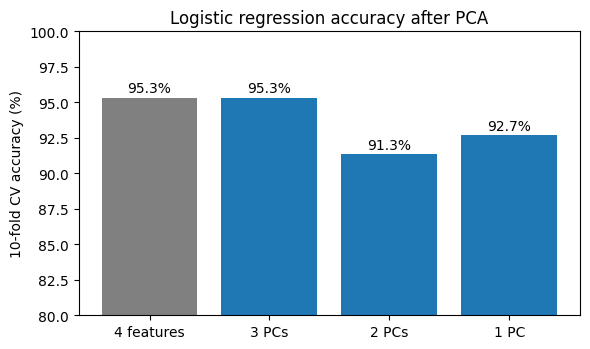

saved results.json


In [5]:
cv = StratifiedKFold(10, shuffle=True, random_state=42)
acc = {}
for k in [4, 3, 2, 1]:
    steps = [StandardScaler()] + ([PCA(n_components=k)] if k < 4 else []) + [LogisticRegression(max_iter=1000)]
    s = cross_val_score(make_pipeline(*steps), X, y, cv=cv)
    acc[k] = (float(s.mean()), float(s.std()))
    print(f"{'original 4 features' if k == 4 else f'PCA {k} component(s)':22s} accuracy {s.mean()*100:.2f}% (± {s.std()*100:.2f})")
fig, ax = plt.subplots(figsize=(6, 3.6))
labels = ["4 features", "3 PCs", "2 PCs", "1 PC"]; vals = [acc[k][0] * 100 for k in [4, 3, 2, 1]]
ax.bar(labels, vals, color=["grey", "tab:blue", "tab:blue", "tab:blue"])
for i, v in enumerate(vals): ax.text(i, v + 0.4, f"{v:.1f}%", ha="center")
ax.set_ylim(80, 100); ax.set_ylabel("10-fold CV accuracy (%)"); ax.set_title("Logistic regression accuracy after PCA")
plt.tight_layout(); plt.savefig(FIG / "accuracy.png", dpi=150); plt.show()
Path("results.json").write_text(json.dumps({"evr": evr.tolist(), "cum": cum.tolist(), "eigen": pca.explained_variance_.tolist(),
    "loadings": loadings.round(4).to_dict(), "std_before": X.std(axis=0).tolist(),
    "corr_petal": float(np.corrcoef(Xs.T)[2, 3]), "recon_mse": float(np.mean((Xs - recon) ** 2)),
    "accuracy": {str(k): v for k, v in acc.items()}}, indent=1))
print("saved results.json")